In [ ]:
import numpy as np
mu0=4*np.pi*1e-7
def Bx_strip(x, z, I, w):
    """
    Magnetic field component Bx for an infinitely thin current strip.

    Parameters:
    x : float or np.ndarray
        Horizontal position (m)
    z : float or np.ndarray
        Height above strip (m)
    I : float
        Total current (A)
    w : float
        Strip width (m)

    Returns:
    Bx : float or np.ndarray
        Magnetic field in x-direction (Tesla)
    """
    return (mu0 * I / (2 * np.pi * w)) * (
        np.arctan((x + w/2) / z) - np.arctan((x - w/2) / z)
    )


def Bz_strip(x, z, I, w):
    """
    Magnetic field component Bz for an infinitely thin current strip.

    Parameters:
    x : float or np.ndarray
        Horizontal position (m)
    z : float or np.ndarray
        Height above strip (m)
    I : float
        Total current (A)
    w : float
        Strip width (m)

    Returns:
    Bz : float or np.ndarray
        Magnetic field in z-direction (Tesla)
    """
    return -(mu0 * I / (4 * np.pi * w)) * (
        np.log((x + w/2)**2 + z**2) - np.log((x - w/2)**2 + z**2)
    )

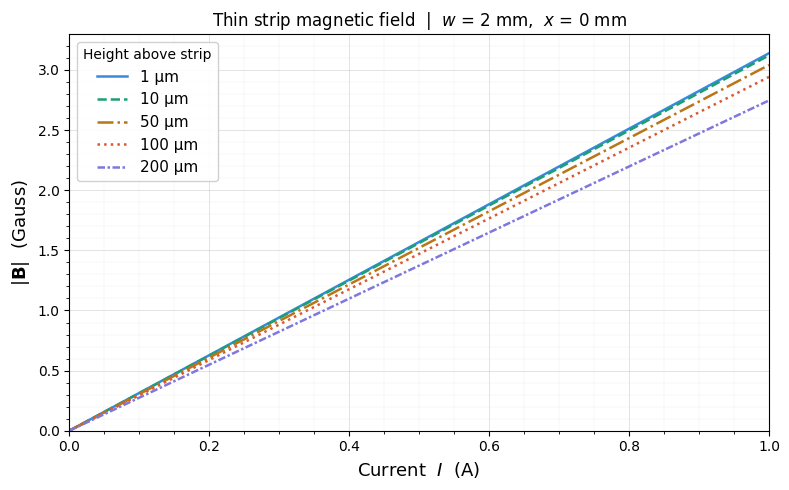

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Physical constants ────────────────────────────────────────────────────────
mu0 = 4 * np.pi * 1e-7
T_TO_GAUSS = 1e4

# ── Strip parameters ──────────────────────────────────────────────────────────
W = 2e-3        # width [m]
X0 = 0.0        # observation x [m]

# ── Distances above strip (now directly from z=0 plane) ───────────────────────
distances = np.array([1e-6, 10e-6, 50e-6, 100e-6, 200e-6])

# ── Current sweep ─────────────────────────────────────────────────────────────
I_vals = np.linspace(0, 1, 200)


# ── New thin-strip field definitions ──────────────────────────────────────────
def Bx_strip(x, z, I, w):
    return (mu0 * I / (2 * np.pi * w)) * (
        np.arctan((x + w/2) / z) - np.arctan((x - w/2) / z)
    )


def Bz_strip(x, z, I, w):
    return -(mu0 * I / (4 * np.pi * w)) * (
        np.log((x + w/2)**2 + z**2) - np.log((x - w/2)**2 + z**2)
    )


def b_magnitude_gauss(x, z, w, I):
    Bx = Bx_strip(x, z, I, w)
    Bz = Bz_strip(x, z, I, w)
    return np.sqrt(Bx**2 + Bz**2) * T_TO_GAUSS


# ── Plot styling ──────────────────────────────────────────────────────────────
colors  = ['#378ADD', '#1D9E75', '#BA7517', '#D85A30', '#7F77DD']
dashes  = ['-', '--', '-.', ':', (0, (3, 1, 1, 1))]
labels  = [f'{d*1e6:.0f} µm' for d in distances]

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

for z, color, dash, label in zip(distances, colors, dashes, labels):
    B_G = b_magnitude_gauss(X0, z, W, I_vals)
    ax.plot(I_vals, B_G, linestyle=dash, color=color, linewidth=1.8, label=label)

ax.set_xlabel('Current  $I$  (A)', fontsize=13)
ax.set_ylabel('$|\\mathbf{B}|$  (Gauss)', fontsize=13)
ax.set_title(
    f'Thin strip magnetic field  |  $w$ = {W*1e3:.0f} mm,  $x$ = {X0*1e3:.0f} mm',
    fontsize=12
)

ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

ax.grid(True, which='major', linewidth=0.5, alpha=0.5)
ax.grid(True, which='minor', linewidth=0.2, alpha=0.3)

ax.legend(title='Height above strip', fontsize=11,
          title_fontsize=10, loc='upper left', framealpha=0.9)

fig.tight_layout()
plt.savefig('thin_strip_bfield.png', dpi=150)
plt.show()

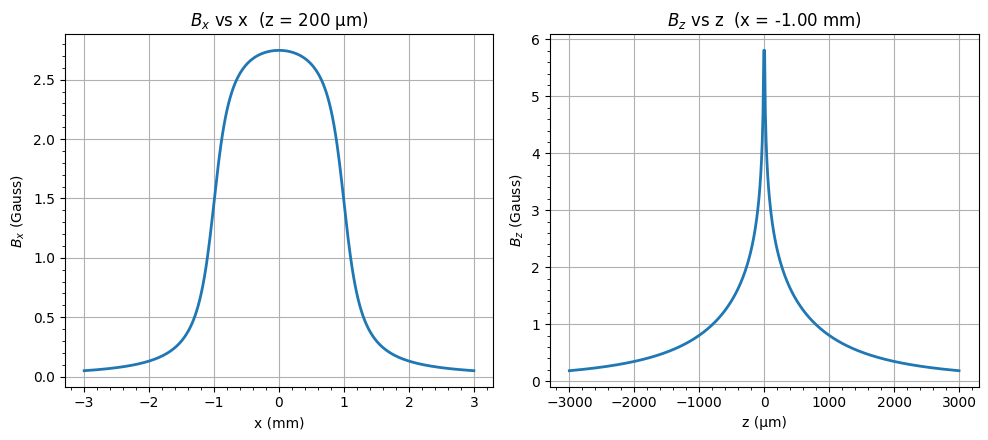

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Constants ────────────────────────────────────────────────────────────────
mu0 = 4 * np.pi * 1e-7
T_TO_GAUSS = 1e4

# ── Strip parameters ─────────────────────────────────────────────────────────
W = 2e-3      # width [m]
I = 1.0       # current [A]

# ── Field definitions (your thin strip) ──────────────────────────────────────
def Bx_strip(x, z, I, w):
    return (mu0 * I / (2 * np.pi * w)) * (
        np.arctan((x + w/2) / z) - np.arctan((x - w/2) / z)
    )

def Bz_strip(x, z, I, w):
    return -(mu0 * I / (4 * np.pi * w)) * (
        np.log((x + w/2)**2 + z**2) - np.log((x - w/2)**2 + z**2)
    )

# ── 1) Bx vs x (at fixed height) ─────────────────────────────────────────────
z_fixed = 200e-6  # 200 µm above strip
x_vals = np.linspace(-3e-3, 3e-3, 500)

Bx_vals = Bx_strip(x_vals, z_fixed, I, W) * T_TO_GAUSS

# ── 2) Bz vs z (at fixed x) ──────────────────────────────────────────────────
x_fixed = -2e-3 # 2 mm off-center
z_vals = np.linspace(-3e-3, 3e-3, 500)


Bz_vals = Bz_strip(x_fixed, z_vals, I, W) * T_TO_GAUSS

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))

# --- Bx vs x ---
axs[0].plot(x_vals * 1e3, Bx_vals, linewidth=2)
axs[0].set_xlabel('x (mm)')
axs[0].set_ylabel('$B_x$ (Gauss)')
axs[0].set_title(f'$B_x$ vs x  (z = {z_fixed*1e6:.0f} µm)')
axs[0].grid(True)
axs[0].xaxis.set_minor_locator(ticker.AutoMinorLocator())
axs[0].yaxis.set_minor_locator(ticker.AutoMinorLocator())

# --- Bz vs z ---
axs[1].plot(z_vals * 1e6, Bz_vals, linewidth=2)
axs[1].set_xlabel('z (µm)')
axs[1].set_ylabel('$B_z$ (Gauss)')
axs[1].set_title(f'$B_z$ vs z  (x = {x_fixed*1e3:.2f} mm)')
axs[1].grid(True)
axs[1].xaxis.set_minor_locator(ticker.AutoMinorLocator())
axs[1].yaxis.set_minor_locator(ticker.AutoMinorLocator())

plt.tight_layout()
plt.show()

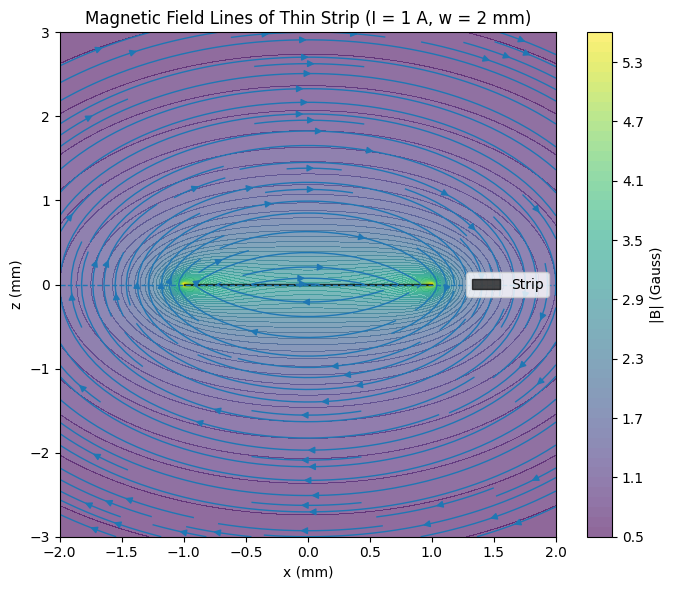

In [19]:
# ── Constants ────────────────────────────────────────────────────────────────
mu0 = 4 * np.pi * 1e-7

# ── Strip parameters ─────────────────────────────────────────────────────────
W = 2e-3   # 2 mm
I = 1.0    # 1 Amp

# ── Grid (avoid z=0 exactly to prevent singularities) ─────────────────────────
x = np.linspace(-2e-3, 2e-3, 300)
z = np.linspace(-3e-3, 3e-3, 300)

X, Z = np.meshgrid(x, z)

# Small offset to avoid division/log issues at z=0
Z_safe = np.where(np.abs(Z) < 1e-9, 1e-9, Z)

# ── Compute field ────────────────────────────────────────────────────────────
Bx = Bx_strip(X, Z_safe, I, W)
Bz = Bz_strip(X, Z_safe, I, W)

# Field magnitude (for coloring)
Bmag = np.sqrt(Bx**2 + Bz**2)

# ── Plot ─────────────────────────────────────────────────────────────────────
plt.figure(figsize=(7, 6))

# Streamlines
plt.streamplot(X * 1e3, Z * 1e3,Bx, Bz,density=1.5,linewidth=1,arrowsize=1)

# Optional: color background by field strength
plt.contourf(X * 1e3, Z * 1e3, Bmag * 1e4, levels=50, alpha=0.6)

plt.colorbar(label='|B| (Gauss)')

# Draw strip location
plt.axhline(0, linestyle='--', linewidth=1)
plt.fill_between(
    [-W/2 * 1e3, W/2 * 1e3],
    -0.01, 0.01,
    color='black',
    alpha=0.7,
    label='Strip'
)

plt.xlabel('x (mm)')
plt.ylabel('z (mm)')
plt.title('Magnetic Field Lines of Thin Strip (I = 1 A, w = 2 mm)')
plt.legend()

plt.xlim(-2, 2)
plt.ylim(-3, 3)

plt.tight_layout()
plt.show()